# Step 1: Import libraries and load cleaned data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned datasets
science_long = pd.read_csv("science_long.csv")
science_wide = pd.read_csv("science_wide.csv")
science_oecd = pd.read_csv("science_oecd_averages.csv")

print("Science long:", science_long.shape)
print("Science wide:", science_wide.shape)
print("OECD averages:", science_oecd.shape)

display(science_long.head())


Science long: (474, 3)
Science wide: (90, 10)
OECD averages: (3, 8)


,Country,Year,Science_Score
0,Argentina,2006,391.0
1,Argentina,2009,401.0
2,Argentina,2012,406.0
3,Argentina,2018,404.0
4,Argentina,2022,406.0


# Science Performance Trend

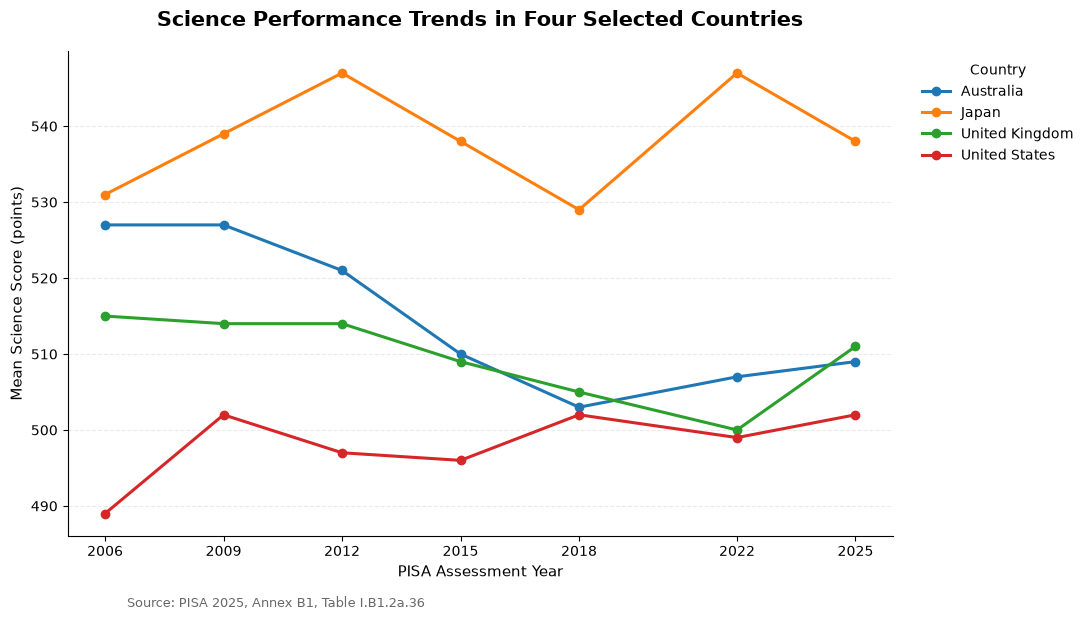

In [4]:

# STEP 2 — Science Performance Trends

selected_countries = [
    "Australia",
    "Japan",
    "United Kingdom",
    "United States"
]

plot_data = science_long[
    science_long["Country"].isin(selected_countries)
]

fig, ax = plt.subplots(figsize=(11, 6))

for country, data in plot_data.groupby("Country"):
    data = data.sort_values("Year")

    ax.plot(
        data["Year"],
        data["Science_Score"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=country
    )

ax.set_title(
    "Science Performance Trends in Four Selected Countries",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("PISA Assessment Year", fontsize=11)
ax.set_ylabel("Mean Science Score (points)", fontsize=11)

ax.set_xticks([2006, 2009, 2012, 2015, 2018, 2022, 2025])

ax.grid(axis="y", linestyle="--", alpha=0.25)

# Move legend outside the plot
ax.legend(
    title="Country",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.12, -0.02,
    "Source: PISA 2025, Annex B1, Table I.B1.2a.36",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout()
plt.savefig(
    "science_performance_trend_4countries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Australia shows a decline in mean science performance between 2006 and 2025, while Japan consistently outperforms the other three selected countries.

# Step 3: Digital Resource Shortage Changes

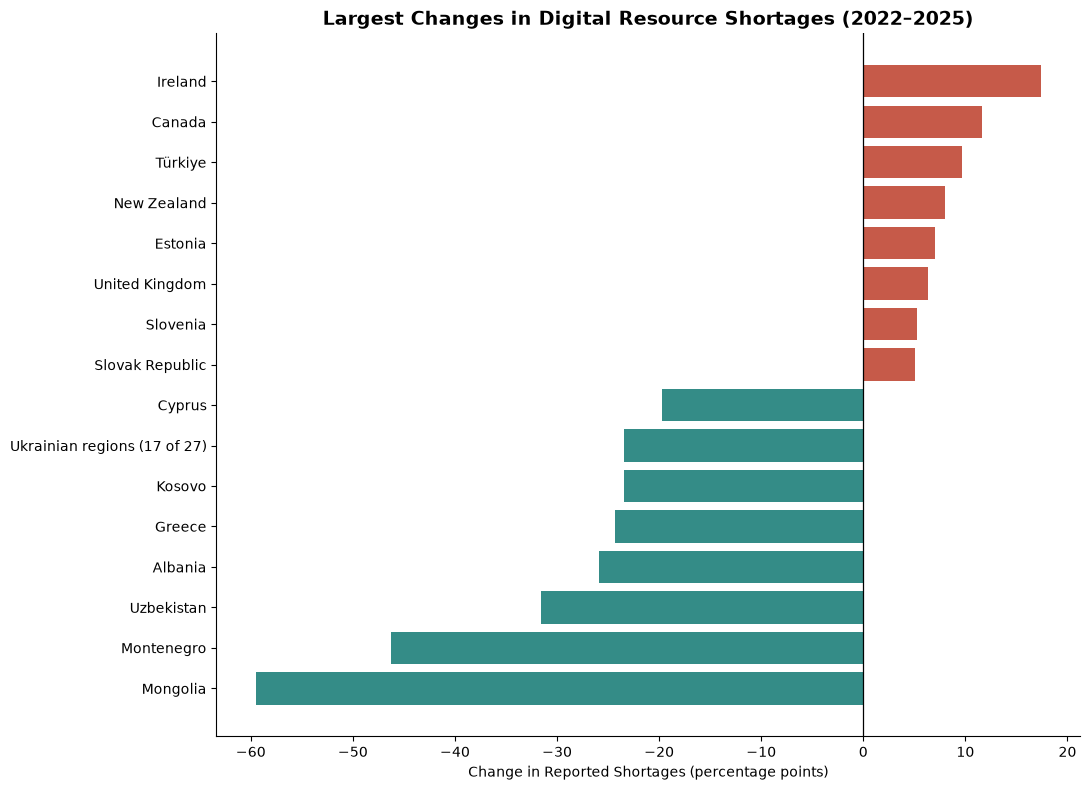

In [5]:
digital = pd.read_csv("digital_clean.csv")

trend = digital.dropna(
    subset=["Digital_Lack_Change"]
).copy()

# 8 largest decreases and 8 largest increases
trend = pd.concat([
    trend.nsmallest(8, "Digital_Lack_Change"),
    trend.nlargest(8, "Digital_Lack_Change")
]).sort_values("Digital_Lack_Change")

colors = np.where(
    trend["Digital_Lack_Change"] >= 0,
    "#C65A49",
    "#348C87"
)

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    trend["Country"],
    trend["Digital_Lack_Change"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.9)

ax.set_title(
    "Largest Changes in Digital Resource Shortages (2022–2025)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Change in Reported Shortages (percentage points)"
)
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "03_digital_shortage_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Step 4: Compare digital resource shortages by socioeconomic status

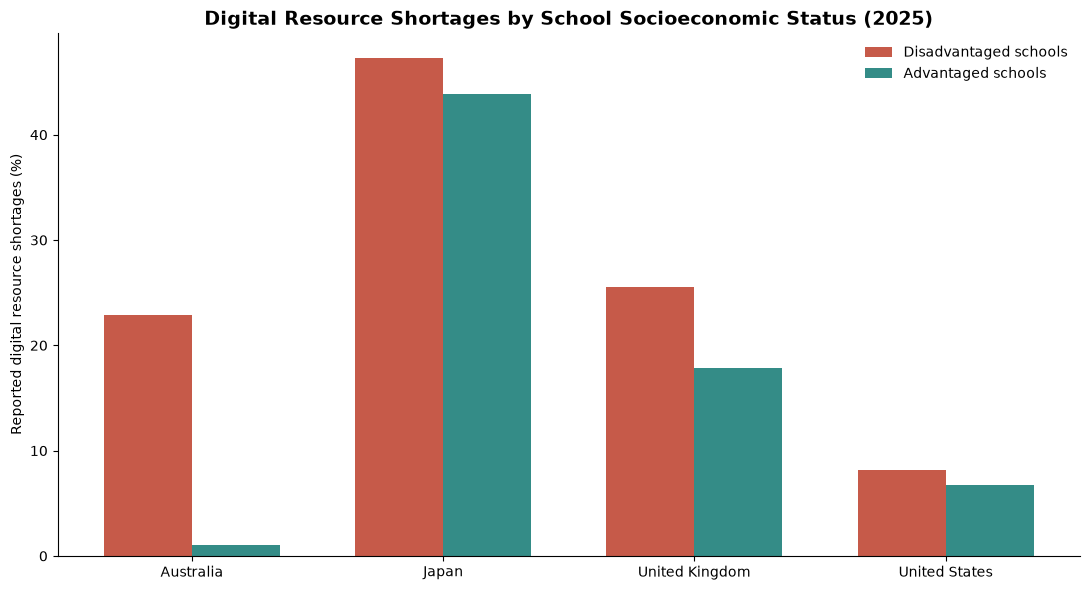

In [7]:
inequality = pd.read_csv("inequality_clean.csv")

selected_countries = [
    "Australia",
    "Japan",
    "United Kingdom",
    "United States"
]

plot_data = inequality[
    inequality["Country"].isin(selected_countries)
].copy()

plot_data = plot_data.dropna(
    subset=["Disadvantaged_2025", "Advantaged_2025"]
)

# Preserve selected country order
plot_data["Country"] = pd.Categorical(
    plot_data["Country"],
    categories=selected_countries,
    ordered=True
)
plot_data = plot_data.sort_values("Country")

x = np.arange(len(plot_data))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    plot_data["Disadvantaged_2025"],
    width,
    label="Disadvantaged schools",
    color="#C65A49"
)

ax.bar(
    x + width / 2,
    plot_data["Advantaged_2025"],
    width,
    label="Advantaged schools",
    color="#348C87"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data["Country"])

ax.set_ylabel("Reported digital resource shortages (%)")

ax.set_title(
    "Digital Resource Shortages by School Socioeconomic Status (2025)",
    fontsize=14,
    fontweight="bold"
)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "04_inequality_grouped_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Step 5 — Digital Resource Shortage Change vs Science Score Change

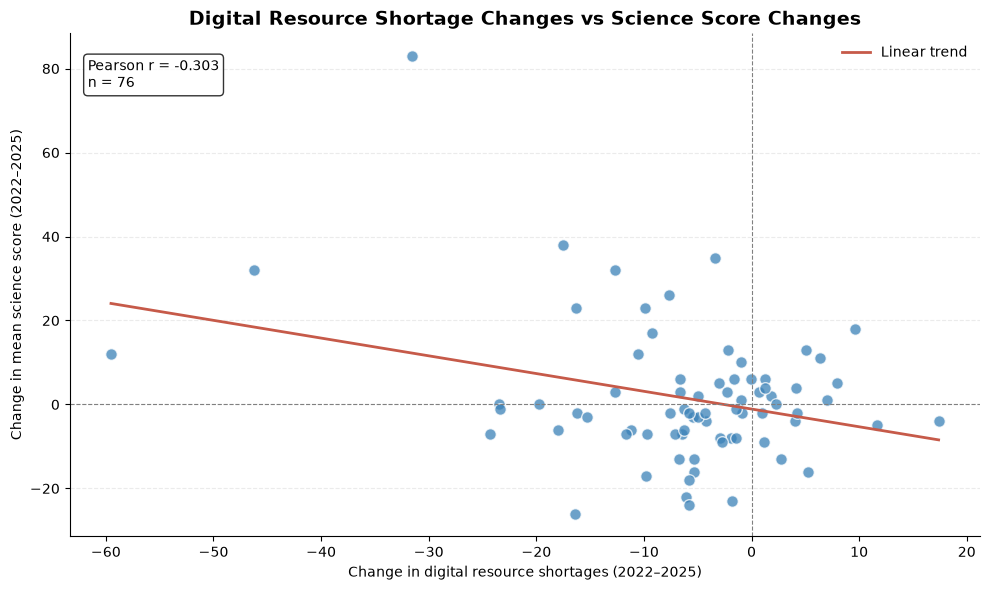

In [9]:
analysis = pd.read_csv("science_digital_analysis.csv")

plot_data = analysis.dropna(
    subset=[
        "Digital_Lack_Change",
        "Science_Change_2022_2025"
    ]
).copy()

x = plot_data["Digital_Lack_Change"]
y = plot_data["Science_Change_2022_2025"]

# Calculate regression line
m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)

# Calculate correlation
corr = x.corr(y)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    x, y,
    alpha=0.75,
    color="#3B82B8",
    edgecolor="white",
    s=70
)

ax.plot(
    x_line,
    m * x_line + b,
    color="#C65A49",
    linewidth=2,
    label="Linear trend"
)

ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.axvline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title(
    "Digital Resource Shortage Changes vs Science Score Changes",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Change in digital resource shortages (2022–2025)"
)

ax.set_ylabel(
    "Change in mean science score (2022–2025)"
)

ax.text(
    0.02, 0.95,
    f"Pearson r = {corr:.3f}\nn = {len(plot_data)}",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(frameon=False)
ax.yaxis.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()

plt.savefig(
    "05_digital_vs_science_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# STEP 6: SOCIOECONOMIC INEQUALITY VS SCIENCE PERFORMANCE

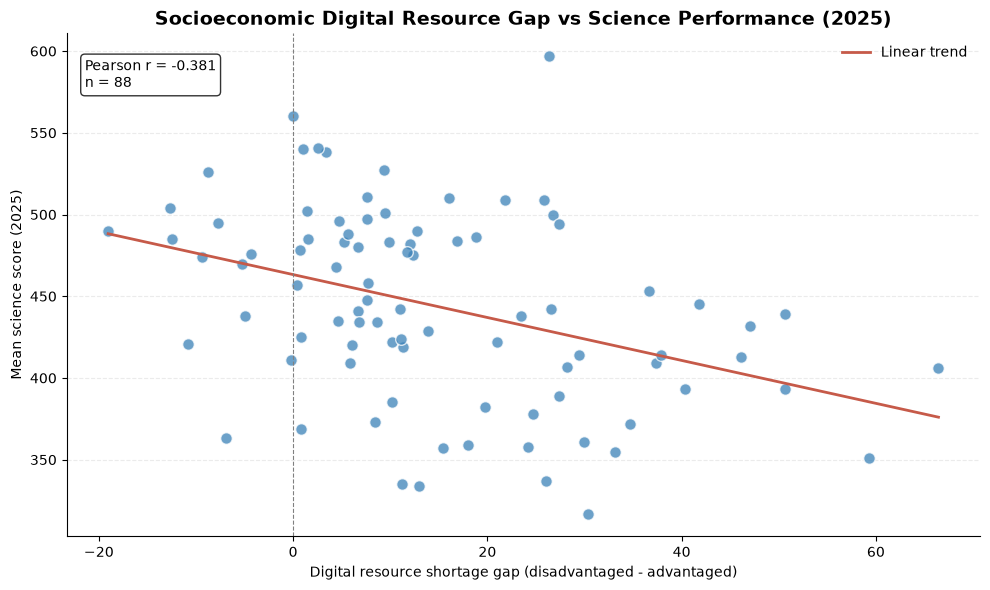

In [11]:
analysis = pd.read_csv("science_inequality_analysis.csv")

plot_data = analysis.dropna(
    subset=["Socioeconomic_Gap_2025", "2025"]
).copy()

x = pd.to_numeric(
    plot_data["Socioeconomic_Gap_2025"], errors="coerce"
)
y = pd.to_numeric(
    plot_data["2025"], errors="coerce"
)

valid = x.notna() & y.notna()
plot_data = plot_data.loc[valid].copy()

x = x.loc[valid]
y = y.loc[valid]

# Correlation and regression line
corr = x.corr(y)
m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    x, y,
    alpha=0.75,
    color="#3B82B8",
    edgecolor="white",
    s=70
)

ax.plot(
    x_line,
    m * x_line + b,
    color="#C65A49",
    linewidth=2,
    label="Linear trend"
)

ax.axvline(
    0, color="grey", linestyle="--", linewidth=0.8
)

ax.set_title(
    "Socioeconomic Digital Resource Gap vs Science Performance (2025)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Digital resource shortage gap (disadvantaged - advantaged)"
)

ax.set_ylabel(
    "Mean science score (2025)"
)

ax.text(
    0.02, 0.95,
    f"Pearson r = {corr:.3f}\nn = {len(plot_data)}",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(frameon=False)
ax.yaxis.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()

plt.savefig(
    "06_inequality_vs_science_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

In [12]:

# STEP 7 — INSPECT RESOURCE-SCIENCE DATA

resource = pd.read_csv(
    "resource_science_relationship_clean.csv"
)

print(resource.columns.tolist())
print(resource.head(5).to_string(index=False))
print("Total rows:", len(resource))


['Resource_Category', 'Resource_Indicator', 'Science_Correlation', 'Science_P_Value', 'Science_Partial_Correlation', 'Science_Partial_P_Value', 'Significant_R', 'Significant_Partial_R']
          Resource_Category                                                                                              Resource_Indicator  Science_Correlation  Science_P_Value  Science_Partial_Correlation  Science_Partial_P_Value  Significant_R  Significant_Partial_R
Shortage of education staff                                                                            Index of shortage of education staff             -0.02359          0.88828                      0.29378                  0.07759          False                  False
Shortage of education staff Gap in the index of shortage of education staff between socio-economically advantaged and disadvantaged schools             -0.04870          0.77523                      0.08001                  0.64274          False                  False
Shor

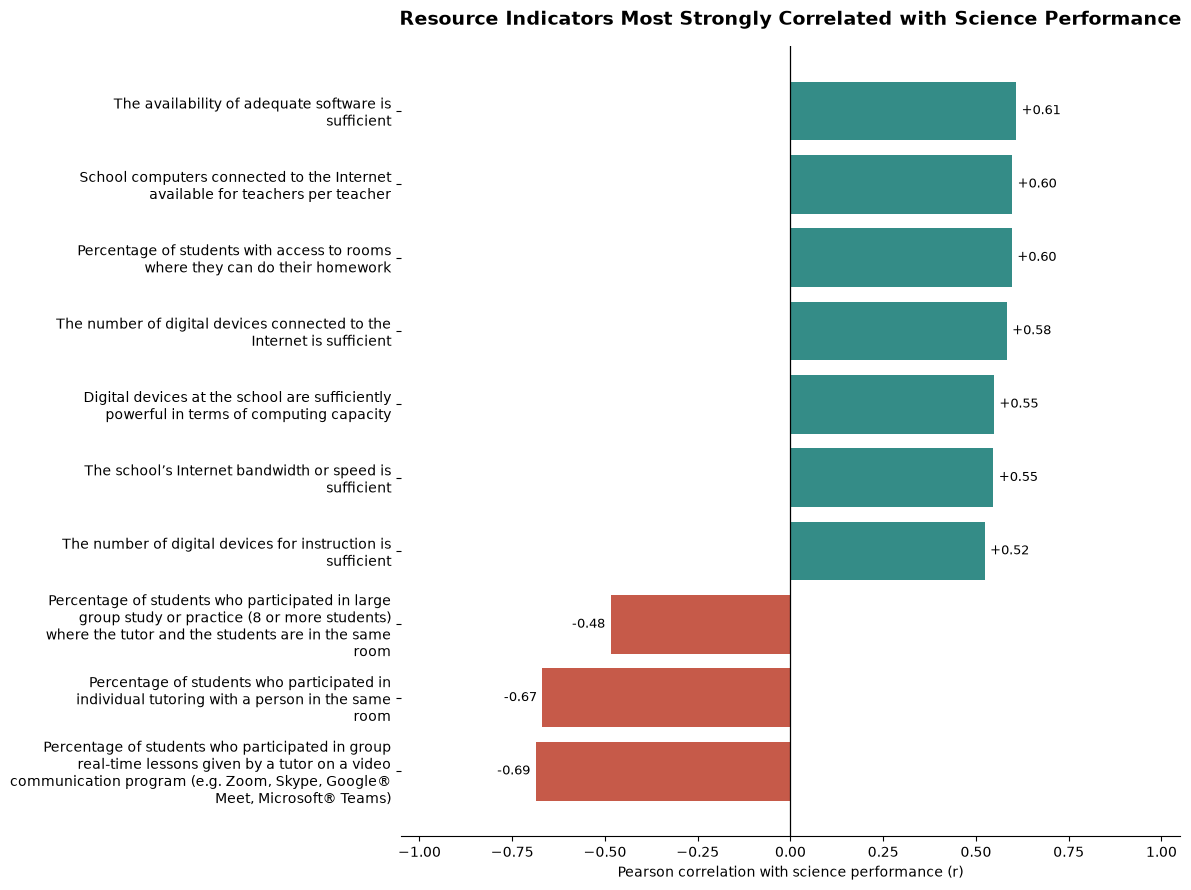

                                                                                                                                                     Resource_Indicator  Science_Correlation  Science_P_Value  Significant_R
Percentage of students who participated in group real-time lessons given by a tutor on a video communication program (e.g. Zoom, Skype, Google® Meet, Microsoft® Teams)             -0.68663          0.00227           True
                                                                          Percentage of students who participated in individual tutoring with a person in the same room             -0.66845          0.00267           True
                    Percentage of students who participated in large group study or practice (8 or more students) where the tutor and the students are in the same room             -0.48486          0.01567           True
                                                                                                            The numb

In [13]:

# STEP 7 — RESOURCE-SCIENCE CORRELATIONS

resource = pd.read_csv(
    "resource_science_relationship_clean.csv"
)

# Keep rows with valid correlation values
plot_data = resource.dropna(
    subset=["Resource_Indicator", "Science_Correlation"]
).copy()

# Select 10 strongest correlations by absolute magnitude
plot_data["Absolute_R"] = (
    plot_data["Science_Correlation"].abs()
)

top10 = (
    plot_data
    .nlargest(10, "Absolute_R")
    .sort_values("Science_Correlation")
    .copy()
)

# Shorten labels for readability
import textwrap

top10["Short_Label"] = top10["Resource_Indicator"].apply(
    lambda s: "\n".join(textwrap.wrap(str(s), width=48))
)

# Colours indicate direction of correlation
colors = np.where(
    top10["Science_Correlation"] < 0,
    "#C65A49",
    "#348C87"
)

fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    top10["Short_Label"],
    top10["Science_Correlation"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.9)

ax.set_title(
    "Resource Indicators Most Strongly Correlated with Science Performance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Pearson correlation with science performance (r)")
ax.set_ylabel("")

# Show correlation values
for bar, value in zip(bars, top10["Science_Correlation"]):
    offset = 0.015 if value >= 0 else -0.015
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.2f}",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

ax.set_xlim(-1.05, 1.05)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()

plt.savefig(
    "07_resource_science_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display indicators and significance
print(top10[[
    "Resource_Indicator",
    "Science_Correlation",
    "Science_P_Value",
    "Significant_R"
]].to_string(index=False))
